# Titanic Survival Prediction

**Question:** which passengers survived, and which features explain it?

**Plan:** explore the data → build a hand-written rule as a baseline → engineer features and check them for redundancy and overfitting → compare models with repeated cross-validation → pick a final model for the Kaggle submission.

## 1. Setup and Data

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

In [2]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 2. Exploratory Analysis
Look for groups with clearly different survival rates; they become the rule and the features later.

### What is the majority class of Survived?

In [5]:
train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [6]:
actual = train['Survived']
prediction = np.zeros(len(train))
accuracy_score(actual, prediction)

0.6161616161616161

### Survived Rate by Sex

In [7]:
train.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

**Insight:** Female have a higher survival chance compared to male.

### Survival Rate by Pclass

In [8]:
train.groupby('Pclass', as_index=False)['Survived'].mean()

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


### Survived data by Sex and Pclass

In [9]:
train.groupby(['Sex', 'Pclass'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass                 
female 1       0.968085     94
       2       0.921053     76
       3       0.500000    144
male   1       0.368852    122
       2       0.157407    108
       3       0.135447    347

### Survival Rate by Title, create Title column

In [10]:
train['Title'] = train['Name'].str.split(',').str[1].str.split('.').str[0].apply(lambda x: x.strip())
test['Title'] = test['Name'].str.split(',').str[1].str.split('.').str[0].apply(lambda x: x.strip())
train.groupby(['Title'], as_index=False)['Survived'].agg(['mean', 'count'])

,Title,mean,count
0,Capt,0.000000,1
1,Col,0.500000,2
2,Don,0.000000,1
3,Dr,0.428571,7
4,Jonkheer,0.000000,1
5,Lady,1.000000,1
6,Major,0.500000,2
7,Master,0.575000,40
8,Miss,0.697802,182
9,Mlle,1.000000,2


**Insights:** Based on the count of these titles do grouping.

In [11]:
for df in [train, test]:
    df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')

train.groupby('Title')['Survived'].agg(['mean', 'count'])

,mean,count
Title,,
Master,0.575000,40
Miss,0.702703,185
Mr,0.156673,517
Mrs,0.793651,126
Rare,0.347826,23


### Age Distribution by Survival

<Axes: xlabel='Age', ylabel='Count'>

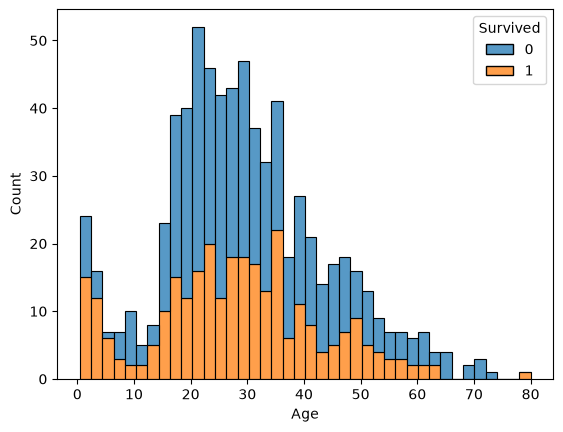

In [12]:
sns.histplot(data=train, x='Age', hue='Survived', bins = 40, multiple='stack')

**Insight:** Most passengers's age is between 20 and 36, but this group is too small which will shrinks the groups with other conditions.

### Survival Rate and Count by Embarked

In [13]:
train.groupby('Embarked')['Survived'].agg(['mean', 'count'])

,mean,count
Embarked,,
C,0.553571,168
Q,0.389610,77
S,0.336957,644


### Survived data by Sex, Pclass, and Embarked

In [14]:
train.groupby(['Sex', 'Pclass', 'Embarked'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass Embarked                 
female 1      C         0.976744     43
              Q         1.000000      1
              S         0.958333     48
       2      C         1.000000      7
              Q         1.000000      2
              S         0.910448     67
       3      C         0.652174     23
              Q         0.727273     33
              S         0.375000     88
male   1      C         0.404762     42
              Q         0.000000      1
              S         0.354430     79
       2      C         0.200000     10
              Q         0.000000      1
              S         0.154639     97
       3      C         0.232558     43
              Q         0.076923     39
              S         0.128302    265

**Insight:** Passenger who is Female, Pclass is 1 or 2 is having a very high survival mean. Beside the female that embarked S, female in third class don't have a low survival mean compared to male.

## 3. Baseline: Rule-based Classifier

### Predict it with the patterns from the "Insight" above

In [15]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & ~((train['Pclass'] == 3) & (train['Embarked'] == 'S'))).astype(int)

accuracy_score(actual, prediction)

0.8114478114478114

### Predict it with Female and first class

In [16]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & (train['Pclass'] == 1)).astype(int)

accuracy_score(actual, prediction)

0.7149270482603816

**Insight:** The "Insight" patterns have a better accuracy score compared to this.

### Apply the patterns from "Insight" on the test dataframe as well

Rules applied: All the female besides those are both 3rd class and Embarked S.

In [17]:
test['Survived'] = ((test['Sex'] == 'female') & ~((test['Pclass'] == 3) & (test['Embarked'] == 'S'))).astype(int)


In [18]:
final_prediction = test[['PassengerId', 'Survived']]
final_prediction.head(10)

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


In [19]:
final_prediction.to_csv('ian_prediction.csv', index=False)

**Insight:** The rule( All the famle besides those are both 3rd class and Embarked S)'s score: 0.77844 is greater than the baseline(0.75). It built by hand from patterns I found.

## 4. Feature Engineering

Use five feature groups: **sex × class**, **family size**, **travel groups**, **title** and **child**. A drop-one check at the end of this section removes any feature that doesn't help CV.

Embarked, Cabin and Fare are dropped: Cabin has many missing values, Embarked adds little once class is known, and Fare mostly repeats Pclass and the size of the ticket group. Age is used only through the Child flag, because it's missing for about 20% of passengers.

### 1. Sex × Class
**Reason:** Sex and class interact. Nearly all 1st/2nd-class women survived, 3rd-class women only about half, and men had low survival in every class. One flag per combination gives every model that interaction directly.

In [20]:
def sex_class(df):
    X = pd.DataFrame(index=df.index)
    for sex in ['female', 'male']:
        for pclass in [1, 2, 3]:
            X[f'{sex}_{pclass}'] = ((df['Sex'] == sex) & (df['Pclass'] == pclass)).astype(int)
    return X

### 2. Family Size (with Alone and Large_Family)
**Reason:** Survival is not linear in family size. Small families (2–4) did best, while people travelling alone and large families (5+) did worse, so the two flags mark both ends.

In [21]:
def family(df):
    X = pd.DataFrame(index=df.index)
    X['Fam_Size'] = df['SibSp'] + df['Parch'] + 1
    X['Alone'] = (X['Fam_Size'] == 1).astype(int)
    X['Large_Family'] = (X['Fam_Size'] >= 5).astype(int)
    return X

### 3. Travel Groups
**Reason:** Passengers on the same ticket travelled together even when not related (friends, maids, nannies), which SibSp/Parch miss. Ticket holders are counted across train and test to get the real group size. No Survived labels are used, so nothing leaks into CV.

In [22]:
ticket_counts = pd.concat([train['Ticket'], test['Ticket']]).value_counts()

def travel_group(df):
    X = pd.DataFrame(index=df.index)
    X['Group_Size'] = df['Ticket'].map(ticket_counts)
    X['Non_Family_Group'] = (X['Group_Size'] > df['SibSp'] + df['Parch'] + 1).astype(int)
    return X

### 4. Title
**Reason:** Title adds age and status information the other groups don't have. "Master" marks young boys, who survived far more often than adult men, and "Mrs"/"Miss" separate married and unmarried women. In a 10×5-fold CV check, adding Title raised accuracy by about 3 points. Uses the grouped Title column from the analysis above; rare titles (Dr, Rev, Col, ...) get their own `Title:Rare` flag.

In [23]:
def title(df):
    X = pd.DataFrame(index=df.index)
    for t in ['Mr', 'Mrs', 'Miss', 'Master', 'Rare']:
        X['Title:' + t] = (df['Title'] == t).astype(int)
    return X

### 5. Child
**Reason:** Children were given priority for the lifeboats. Age is missing for many passengers, but the title Master marks young boys even when their age is unknown, so a passenger counts as a child if Age < 13 or Title is Master.

In [24]:
def child(df):
    is_child = (df['Age'] < 13) | (df['Title'] == 'Master')   # missing Age compares as False
    return pd.DataFrame({'Child': is_child.astype(int)}, index=df.index)

Combine the groups into the model input (all candidate features, before any are dropped).

In [25]:
feature_groups = {
    'Sex x Class': sex_class,
    'Family Size': family,
    'Travel Groups': travel_group,
    'Title': title,
    'Child': child,
}

def preprocess(df, groups=feature_groups):
    return pd.concat([make(df) for make in groups.values()], axis=1)

X, y, X_test = preprocess(train), train['Survived'], preprocess(test)
print(X.shape, X_test.shape)
print('Missing values (train, test):', X.isnull().sum().sum(), X_test.isnull().sum().sum())
X.head()

(891, 17) (418, 17)
Missing values (train, test): 0 0


,female_1,female_2,female_3,male_1,male_2,male_3,Fam_Size,Alone,Large_Family,Group_Size,Non_Family_Group,Title:Mr,Title:Mrs,Title:Miss,Title:Master,Title:Rare,Child
0,0,0,0,0,0,1,2,0,0,1,0,1,0,0,0,0,0
1,1,0,0,0,0,0,2,0,0,2,0,0,1,0,0,0,0
2,0,0,1,0,0,0,1,1,0,1,0,0,0,1,0,0,0
3,1,0,0,0,0,0,2,0,0,2,0,0,1,0,0,0,0
4,0,0,0,0,0,1,1,1,0,1,0,1,0,0,0,0,0


### Feature correlation
Before choosing features, check how they relate to each other and to `Survived`. Two features with |r| near 1 carry almost the same information, and keeping both mostly gives a model more room to fit noise.

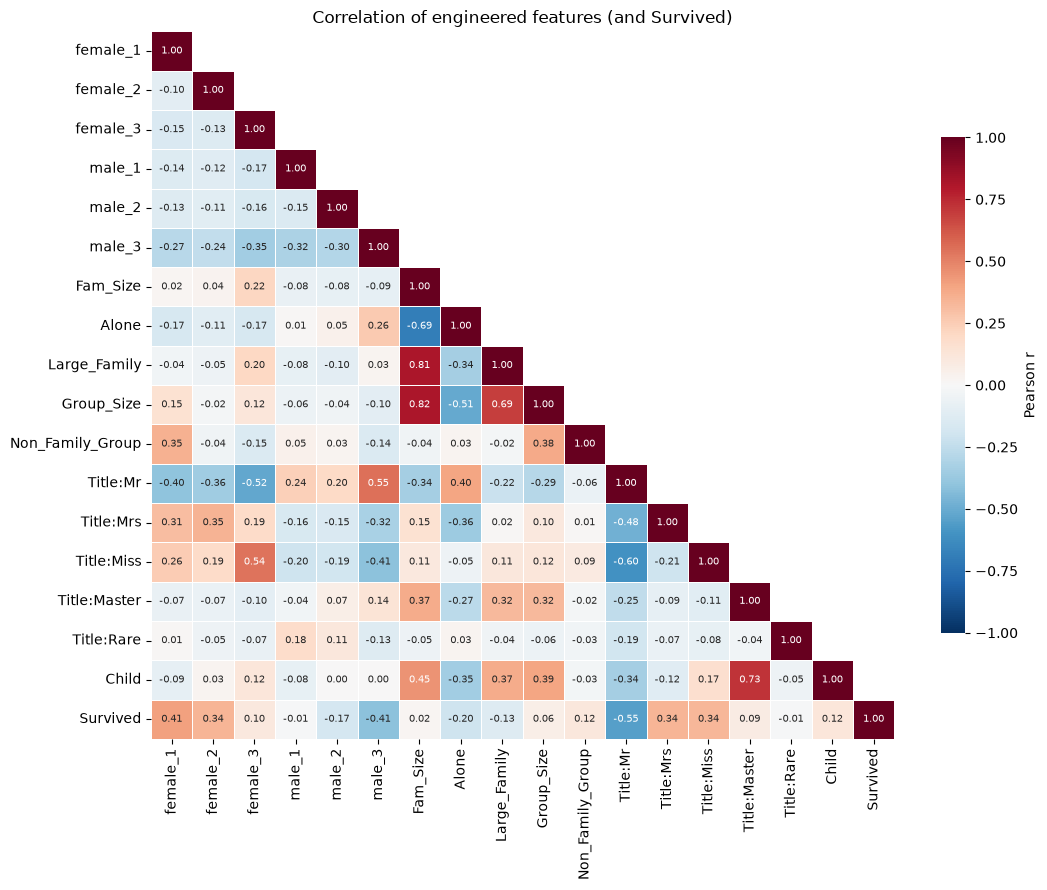

In [26]:
corr = pd.concat([X, y], axis=1).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # show each pair once

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5,
            cbar_kws={'shrink': 0.7, 'label': 'Pearson r'}, ax=ax)
ax.set_title('Correlation of engineered features (and Survived)')
plt.tight_layout()
plt.show()

**Insight:** Three pairs stand out: `Fam_Size`–`Group_Size` (0.82), `Fam_Size`–`Large_Family` (0.81) and `Child`–`Title:Master` (0.73). Each one mostly repeats another feature, so they are the first suspects for the drop-one check below.

`Fam_Size` has almost no linear link to survival (r = 0.02) because survival rises and then falls with family size, which is why it is also split into `Alone` and `Large_Family`. The strongest single signals are `Title:Mr` (−0.55), `female_1` (+0.41) and `male_3` (−0.41).

### Drop-one check (overfitting)
A feature that only fits noise raises training accuracy without raising CV. Starting from all features, try removing each one and keep the removal that gives the highest mean CV across three models (L2 logistic regression, random forest, L1 interaction model), then repeat. Stop when every removal lowers CV. Encoded blocks (the 6 sex × class flags and the 4 main titles) are tested as one unit, because removing a single dummy loses no information.

Note: picking features with CV makes the final CV slightly optimistic, so only clear ties are dropped.

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
check_models = [
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42),
    make_pipeline(PolynomialFeatures(degree=2, interaction_only=True, include_bias=False), StandardScaler(),
                  LogisticRegression(l1_ratio=1.0, C=0.1, solver='liblinear', max_iter=5000)),
]

def mean_cv(X_try):
    return np.mean([cross_val_score(m, X_try, y, cv=rcv, n_jobs=-1).mean() for m in check_models])

candidates = {
    'Sex x Class flags': list(sex_class(train).columns),
    'Title Mr/Mrs/Miss/Master': ['Title:Mr', 'Title:Mrs', 'Title:Miss', 'Title:Master'],
}
in_blocks = sum(candidates.values(), [])
candidates.update({col: [col] for col in X.columns if col not in in_blocks})

dropped = []
best = mean_cv(X)
history = [{'step': 'all features', 'n_features': X.shape[1], 'mean CV': best}]
while True:
    trials = {name: mean_cv(X.drop(columns=dropped + cols))
              for name, cols in candidates.items() if not set(cols) <= set(dropped)}
    name = max(trials, key=trials.get)
    if trials[name] < best:
        break
    dropped += candidates[name]
    best = trials[name]
    history.append({'step': 'drop ' + name, 'n_features': X.shape[1] - len(dropped), 'mean CV': best})

print('dropped:', dropped)
pd.DataFrame(history)

dropped: ['Fam_Size', 'Non_Family_Group', 'Child']


,step,n_features,mean CV
0,all features,17,0.830229
1,drop Fam_Size,16,0.831351
2,drop Non_Family_Group,15,0.831724
3,drop Child,14,0.831913


Rebuild the inputs without the dropped features.

In [28]:
def preprocess(df, groups=feature_groups):
    X = pd.concat([make(df) for make in groups.values()], axis=1)
    return X.drop(columns=[c for c in dropped if c in X.columns])

X, X_test = preprocess(train), preprocess(test)
print(X.shape, X_test.shape)
X.columns.tolist()

(891, 14) (418, 14)


['female_1',
 'female_2',
 'female_3',
 'male_1',
 'male_2',
 'male_3',
 'Alone',
 'Large_Family',
 'Group_Size',
 'Title:Mr',
 'Title:Mrs',
 'Title:Miss',
 'Title:Master',
 'Title:Rare']

### Feature Group Test

With the final feature set, add one feature group at a time and score each set with 10×5-fold repeated stratified CV (50 fits per bar), so a gain has to hold across many splits, not just one lucky fold. Error bars show the standard deviation across the 50 folds.

In [29]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
test_models = {
    'LogRe': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42),
}

group_names = list(feature_groups)
rows, prev_cols = [], 0
for k in range(1, len(group_names) + 1):
    label = group_names[0] if k == 1 else '+ ' + group_names[k - 1]
    X_step = preprocess(train, {n: feature_groups[n] for n in group_names[:k]})
    if X_step.shape[1] == prev_cols:   # every column of this group was dropped
        continue
    prev_cols = X_step.shape[1]
    for model_name, model in test_models.items():
        scores = cross_val_score(model, X_step, y, cv=rcv)
        rows.append({'step': label, 'model': model_name, 'n_features': X_step.shape[1],
                     'cv': scores.mean(), 'std': scores.std()})

group_results = pd.DataFrame(rows)
group_results

,step,model,n_features,cv,std
0,Sex x Class,LogRe,6,0.772960,0.023228
1,Sex x Class,Random Forest,6,0.773072,0.023116
2,+ Family Size,LogRe,8,0.800458,0.025812
3,+ Family Size,Random Forest,8,0.805280,0.027992
4,+ Travel Groups,LogRe,9,0.798994,0.023258
5,+ Travel Groups,Random Forest,9,0.814710,0.026310
6,+ Title,LogRe,14,0.831874,0.024741
7,+ Title,Random Forest,14,0.832889,0.023360


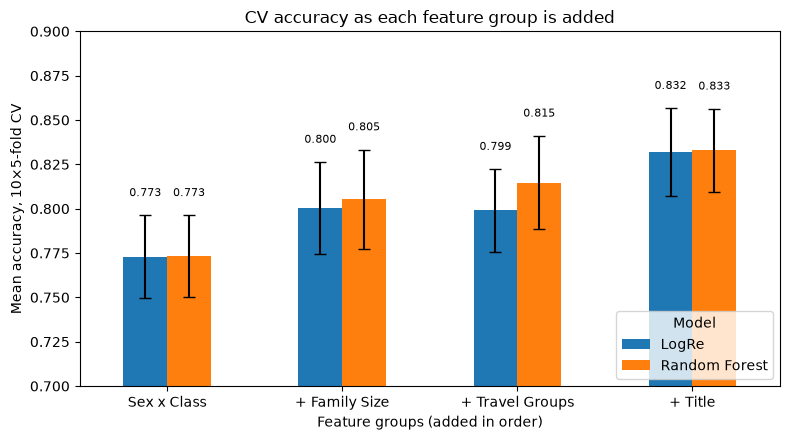

In [30]:
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer

order = group_results['step'].unique()
means = group_results.pivot(index='step', columns='model', values='cv').loc[order]
stds = group_results.pivot(index='step', columns='model', values='std').loc[order]

ax = means.plot.bar(yerr=stds, capsize=4, rot=0, figsize=(8, 4.5))
for bars in ax.containers:
    if isinstance(bars, BarContainer):
        ax.bar_label(bars, fmt='%.3f', padding=12, fontsize=8)
ax.set_ylim(0.70, 0.90)
ax.set_xlabel('Feature groups (added in order)')
ax.set_ylabel('Mean accuracy, 10×5-fold CV')
ax.set_title('CV accuracy as each feature group is added')
ax.legend(title='Model', loc='lower right')
plt.tight_layout()
plt.show()

## 5. Modeling
Compare models on the final features. Quick 5-fold CV first, then 10×5 repeated CV for the close calls, always watching the train/CV gap.

### Cross-validation setup

In [31]:
from sklearn.model_selection import cross_validate

results = {}
def evaluate(name, model):
    scores = cross_validate(model, X, y, cv=5, return_train_score=True)
    cv_acc = scores['test_score'].mean()
    gap = scores['train_score'].mean() - cv_acc
    results[name] = {'cv': cv_acc, 'gap': gap}
    print(name, 'cv:', round(cv_acc, 4), 'gap:', round(gap, 4))

cv is the average accuracy. Keeping tracking the gap(training accuracy - cv) to avoid overfitting.

### Base models

In [32]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

models_n = {
    'Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'LogRe': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'MLP': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(31, ), max_iter=1000, early_stopping=True, solver='adam', random_state=42))
}

for name, model in models_n.items():
    evaluate(name, model)

Tree cv: 0.8104 gap: 0.0401
LogRe cv: 0.8227 gap: 0.0092


MLP cv: 0.8025 gap: 0.016


**Insight:** Logistic Regression and Random Forest tie at 0.823. Decision Tree has the largest gap (0.040), so it overfits the most.

### Ensemble models

#### Simple combination (soft voting)

In [33]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier(list(models_n.items()), voting='soft')
evaluate('Voting', voting_model)

Voting cv: 0.8104 gap: 0.0319


#### Bagging & Random Forest

In [34]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=6, random_state=42), n_estimators=200, random_state=42)

random_forest = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)

evaluate('Bagging', bagging_model)
evaluate('Random Forest', random_forest)

Bagging cv: 0.8182 gap: 0.0342


Random Forest cv: 0.8227 gap: 0.0213


#### Boosting

In [35]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=42)
evaluate('Ada_Boosted', ada_model)

Ada_Boosted cv: 0.8283 gap: 0.0059


#### Stacking

In [36]:
from sklearn.ensemble import StackingClassifier

stack_model = StackingClassifier(
    estimators=[
        ('LogRe', models_n['LogRe']),
        ('Random Forest', random_forest),
        ('MLP', models_n['MLP']),
        ('Ada_Boosted', ada_model)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

evaluate('Stacking', stack_model)

Stacking cv: 0.8316 gap: 0.0059


In [37]:
pd.DataFrame(results).T.sort_values('cv', ascending=False)

,cv,gap
Stacking,0.831624,0.005917
Ada_Boosted,0.828259,0.005914
LogRe,0.822692,0.009237
Random Forest,0.822679,0.021317
Bagging,0.818185,0.034228
Voting,0.810382,0.031929
Tree,0.810370,0.040079
MLP,0.802492,0.015970


**Insight:** Stacking has the best single 5-fold CV (0.832) with a small gap. Single 5-fold scores move by about a point from run to run, so the 10×5 comparisons below are more reliable.

### L1 Logistic Regression with Interaction Terms

`PolynomialFeatures(degree=2, interaction_only=True)` adds the product of every two features, so a linear model can use combinations such as `female_3 × Large_Family`. The 14 features plus 91 products give 105 columns.

With `l1_ratio=1.0` (lasso), many weights become exactly zero, so the model selects its own interaction terms. C is tuned with `GridSearchCV` over the 10×5 repeated CV.

In [38]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

pair_model = make_pipeline(
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
    StandardScaler(),
    LogisticRegression(l1_ratio=1.0, solver='liblinear', max_iter=5000),
)
search = GridSearchCV(pair_model, {'logisticregression__C': [0.03, 0.05, 0.1, 0.2, 0.5]}, cv=rcv, n_jobs=-1)
search.fit(X, y)
print('best C:', search.best_params_['logisticregression__C'], '| 10x5 cv:', round(search.best_score_, 4))

pair_model = search.best_estimator_
evaluate('L1 Pairs', pair_model)

best C: 0.1 | 10x5 cv: 0.8304
L1 Pairs cv: 0.8294 gap: 0.0059


Non-zero weights after the lasso fit (sorted by size; positive means more likely to survive):

In [39]:
names = pair_model[0].get_feature_names_out(X.columns)
coef = pd.Series(pair_model[-1].coef_.ravel(), index=names)
kept = coef[coef != 0].sort_values(key=abs, ascending=False)
print(f'kept {len(kept)} of {len(coef)}')
kept.round(3)

kept 20 of 105


female_1                     0.781
male_3 Title:Mr             -0.542
Title:Mr                    -0.534
Large_Family Group_Size     -0.377
female_2                     0.347
male_2 Title:Mr             -0.302
Large_Family Title:Master   -0.264
Title:Master                 0.249
male_2 Title:Rare           -0.164
female_2 Group_Size          0.162
Alone Group_Size             0.144
male_2 Title:Master          0.104
male_2 Group_Size           -0.093
female_3 Large_Family       -0.082
Alone Title:Rare            -0.044
Alone Title:Mr              -0.032
Title:Rare                  -0.028
female_2 Title:Miss          0.016
female_1 Large_Family        0.014
Alone Title:Mrs              0.012
dtype: float64

In [40]:
pd.DataFrame(results).T.sort_values('cv', ascending=False)

,cv,gap
Stacking,0.831624,0.005917
L1 Pairs,0.829383,0.005913
Ada_Boosted,0.828259,0.005914
LogRe,0.822692,0.009237
Random Forest,0.822679,0.021317
Bagging,0.818185,0.034228
Voting,0.810382,0.031929
Tree,0.810370,0.040079
MLP,0.802492,0.015970


#### Model comparison (10×5-fold CV)
All models use the same 14 features and the same 50 folds. Linear and ridge regression output a number, which `ThresholdRegressor` turns into a 0/1 prediction with a 0.5 cutoff.

In [41]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

class ThresholdRegressor(ClassifierMixin, BaseEstimator):
    """Use a regression model as a classifier: predict 1 when the output is >= 0.5."""
    def __init__(self, regressor):
        self.regressor = regressor
    def fit(self, X, y):
        self.regressor_ = clone(self.regressor).fit(X, y)
        self.classes_ = np.array([0, 1])
        return self
    def predict(self, X):
        return (self.regressor_.predict(X) >= 0.5).astype(int)

compare_models = {
    'L1 Interactions LogRe': pair_model,
    'Linear Regression (0.5 cutoff)': make_pipeline(StandardScaler(), ThresholdRegressor(LinearRegression())),
    'Ridge (0.5 cutoff)': make_pipeline(StandardScaler(), ThresholdRegressor(Ridge(alpha=10))),
    'LogRe (L2)': models_n['LogRe'],
    'Gradient Boosting (depth 2)': GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.1, random_state=42),
}

comparison = pd.DataFrame(
    {'CV accuracy': [cross_val_score(m, X, y, cv=rcv, n_jobs=-1).mean() for m in compare_models.values()]},
    index=pd.Index(list(compare_models), name='Model'),
)
comparison.style.format('{:.1%}')

,CV accuracy
Model,
L1 Interactions LogRe,83.0%
Linear Regression (0.5 cutoff),83.2%
Ridge (0.5 cutoff),83.2%
LogRe (L2),83.2%
Gradient Boosting (depth 2),83.0%


**Insight:** The L1 interaction model reaches 83.0% with a small gap while using 20 of its 105 columns. The five models are within 0.2 points of each other (83.0–83.2%), but adding feature groups moved accuracy by about 6 points (77.3% → 83.2%), so better features are worth more than a different model.

### Family Survival Rate Features + Per-Group Logistic Regression

Build a family ID (`Family_Key`) from surname + ticket. Train and test are combined, so a family split across the two files is still matched.

In [42]:
for df in [train, test]:
    df['Surname'] = df['Name'].str.split(',').str[0].str.strip()
    df['Family_Key'] = df['Surname'] + '_' + df['Ticket']

info_cols = ['PassengerId', 'Family_Key', 'Sex', 'Pclass']
X_fam = pd.concat([X, train[info_cols]], axis=1)
X_test_fam = pd.concat([X_test, test[info_cols]], axis=1)

family_sizes = pd.concat([train['Family_Key'], test['Family_Key']]).value_counts()
print('families with 2+ members:', (family_sizes >= 2).sum())

families with 2+ members: 176


**New features** (computed from other members of the same `Family_Key` who are in the training labels):
- `Family_Surv_Rate`: fraction of those members who survived; -1 when none are labeled.
- `Family_Known`: 1 when at least one other member is labeled, so a missing rate isn't confused with a rate of 0.
- `Family_Surv_Smooth`: Laplace-smoothed rate, (survivors + 1) / (labeled members + 2). Small families are pulled toward 0.5, so rates backed by more people carry more weight.

**Leakage control:** the rates are rebuilt inside each CV fold from that fold's training rows only, and a passenger's own label is always excluded.

**Model:** `SixGroupLR` fits a separate logistic regression for each Sex × Pclass cell. Only the female 3rd-class model uses `Family_Surv_Smooth`; the other five use `Family_Surv_Rate`.

In [43]:
class SixGroupLR(ClassifierMixin, BaseEstimator):
    """One logistic regression per Sex/Pclass group, with optional family survival features.

    Family survival only uses labels the model was fitted on, and never a passenger's own label,
    so CV scores are not leaked.
    """
    groups = [(s, p) for s in ['female', 'male'] for p in [1, 2, 3]]

    def __init__(self, family=True, smooth_groups=(('female', 3),), C=1.0):
        self.family = family
        self.smooth_groups = smooth_groups
        self.C = C

    def _family_features(self, X):
        known = self.known_
        totals = known.groupby('Family_Key')['Survived'].agg(['sum', 'count'])
        survivors = X['Family_Key'].map(totals['sum']).fillna(0)
        members = X['Family_Key'].map(totals['count']).fillna(0)
        own = X['PassengerId'].map(known.set_index('PassengerId')['Survived'])
        survivors = survivors - own.fillna(0)          # leave the passenger out
        members = members - own.notna()
        F = pd.DataFrame(index=X.index)
        F['Family_Surv_Rate'] = np.where(members > 0, survivors / members.clip(lower=1), -1)
        F['Family_Known'] = (members > 0).astype(int)
        F['Family_Surv_Smooth'] = (survivors + 1) / (members + 2)
        return F

    def _inputs(self, X, group):
        base = X.drop(columns=info_cols + list(sex_class(train).columns), errors='ignore')
        if not self.family:
            return base
        F = self._family_features(X)
        survival_col = 'Family_Surv_Smooth' if group in self.smooth_groups else 'Family_Surv_Rate'
        return pd.concat([base, F[[survival_col, 'Family_Known']]], axis=1)

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.known_ = X[['PassengerId', 'Family_Key']].assign(Survived=y)
        self.classes_ = np.array([0, 1])
        self.models_ = {}
        for group in self.groups:
            mask = (X['Sex'] == group[0]) & (X['Pclass'] == group[1])
            if y[mask].nunique() < 2:                     # only one outcome seen: predict it
                self.models_[group] = int(y[mask].mode()[0]) if mask.any() else 0
                continue
            model = make_pipeline(StandardScaler(), LogisticRegression(C=self.C, max_iter=5000))
            self.models_[group] = model.fit(self._inputs(X[mask], group), y[mask])
        return self

    def predict(self, X):
        pred = pd.Series(0, index=X.index)
        for group, model in self.models_.items():
            mask = (X['Sex'] == group[0]) & (X['Pclass'] == group[1])
            if not mask.any():
                continue
            pred[mask] = model if isinstance(model, int) else model.predict(self._inputs(X[mask], group))
        return pred.to_numpy()

Score the per-group model with and without family features, against the earlier models, on the same 10×5-fold CV.

In [44]:
family_models = {
    'Per-group LogRe + family (smoothed F3)': (SixGroupLR(family=True), X_fam),
    'Per-group LogRe + family (raw rate)': (SixGroupLR(family=True, smooth_groups=()), X_fam),
    'Per-group LogRe, no family': (SixGroupLR(family=False), X_fam),
    'Decision Tree': (models_n['Tree'], X),
    'L1 Interactions LogRe': (pair_model, X),
}
family_results = pd.Series(
    {name: cross_val_score(model, data, y, cv=rcv, n_jobs=-1).mean() for name, (model, data) in family_models.items()},
    name='CV accuracy',
).sort_values()
family_results.map('{:.2%}'.format)

Per-group LogRe, no family                82.81%
L1 Interactions LogRe                     83.04%
Decision Tree                             83.06%
Per-group LogRe + family (raw rate)       83.48%
Per-group LogRe + family (smoothed F3)    83.89%
Name: CV accuracy, dtype: str

**Insight:** The family rates lift the per-group model from 82.8% to 83.5%, and smoothing the female 3rd-class rate takes it to 83.9%, the best CV in this notebook. That is about 0.9 points above the L1 interaction model, still small next to the roughly ±2.4-point spread between folds.

## 6. Final Model for Submission

In [45]:
final_model = pair_model
final_model.fit(X, y)

final_submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': final_model.predict(X_test)})
final_submission.to_csv('ian_final_prediction.csv', index=False)
final_submission['Survived'].value_counts()

Survived
0    254
1    164
Name: count, dtype: int64

## 7. Summary
- **Baselines:** predicting that everyone died gives 61.6%. The hand-written rule (women survive, except 3rd-class women from Southampton) scored 0.778 on Kaggle.
- **Features did most of the work.** With 10×5 CV, Sex × Class alone reaches 77.3%, family size brings it to about 80%, and Title to about 83%.
- **Redundant features were removed.** The heatmap flagged three near-copies (`Fam_Size`, `Non_Family_Group`, `Child`), and the drop-one check confirmed that removing them doesn't hurt CV (17 → 14 features).
- **The choice of model mattered much less.** On the same features, linear, ridge, logistic, boosting and L1 interaction models all land between 83.0% and 83.2%, and the ensembles don't beat plain logistic regression.
- **Best CV:** per-group logistic regression with family survival rates, 83.9%. The submission uses the simpler L1 interaction model (83.0%), which doesn't depend on other passengers' labels.
- **Caveat:** scores vary by about ±2.4 points between folds, and Kaggle's public leaderboard has usually come in a few points below CV.